# 04 — Vergleich gespeicherter Backtest-Runs

Führt **keinen** Backtest aus, liest ausschließlich bereits gespeicherte Runs aus `data/processed/backtests/` — bleibt dadurch in Sekunden reproduzierbar.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))

from IPython.display import display
from Src.backtest import runs as bt_runs

runs = bt_runs.list_runs(refresh_index=True)
display(runs)

,run_id,created_at,label,description,strategy_name,clique_variant,baskets,backtest_start,backtest_end,fingerprint,n_trades,sharpe_daily,cagr_daily,max_drawdown_pct,runtime_seconds
0,20260811-161423_pairwise-basket1-baseline_3782...,2026-08-11T16:14:23.784167+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3782a41a,76,-4.297511,-0.066698,-0.030673,9.471143
1,20260811-161145_pairwise-basket1234-topo-break...,2026-08-11T16:11:45.777566+00:00,pairwise_basket1234_topo_break_on,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,"[Basket 1, Basket 2, Basket 3, Basket 4]",2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,7b320681,217,-7.241190,-0.171392,-0.073187,59.386479
2,20260811-160944_pairwise-basket1234-topo-break...,2026-08-11T16:09:44.099375+00:00,pairwise_basket1234_topo_break_off,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,"[Basket 1, Basket 2, Basket 3, Basket 4]",2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,141682cf,212,-7.251162,-0.169602,-0.072392,34.072010
3,20260811-160539_pairwise-basket1-topo-break-on...,2026-08-11T16:05:39.281932+00:00,pairwise_basket1_topo_break_on,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,8cf8b893,76,-4.297511,-0.066698,-0.030673,19.793534
4,20260811-160444_pairwise-basket1-topo-break-of...,2026-08-11T16:04:44.391237+00:00,pairwise_basket1_topo_break_off,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3782a41a,76,-4.297511,-0.066698,-0.030673,9.136886
5,20260811-005244_pairwise-basket1-residual-24h_...,2026-08-11T00:52:44.080658+00:00,pairwise_basket1_residual_24h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5b80acd7,5,-1.321198,-0.003622,-0.003639,2.249917
6,20260811-005231_pairwise-basket1-residual-12h_...,2026-08-11T00:52:31.073432+00:00,pairwise_basket1_residual_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5eb79671,12,-2.705278,-0.015151,-0.007469,1.218577
7,20260811-005219_pairwise-basket1-residual-6h_3...,2026-08-11T00:52:19.094698+00:00,pairwise_basket1_residual_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3a38b525,6,-2.359453,-0.007265,-0.004354,2.005559
8,20260811-005206_pairwise-basket1-raw-12h_73ae444b,2026-08-11T00:52:06.223666+00:00,pairwise_basket1_raw_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,73ae444b,130,-4.562500,-0.075088,-0.036685,9.066313
9,20260811-005146_pairwise-basket1-raw-6h_6d7ff157,2026-08-11T00:51:46.243373+00:00,pairwise_basket1_raw_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,6d7ff157,115,-4.774419,-0.076830,-0.036143,9.118448


## Runs auswählen

Run-IDs unten eintragen (Default: alle vorhandenen Runs).

In [ ]:
RUN_IDS = runs["run_id"].tolist()  # bei Bedarf auf eine Auswahl einschraenken
RUN_IDS

# Kadenz-/Variantenvergleich (raw/residual x 6h/12h/24h), Basket 1, siehe
# 04_backtest/01_pairwise_bollinger.ipynb -- CLIQUE_VARIANT dort pro Lauf
# geaendert und mit eigenem RUN_LABEL gespeichert.
CADENCE_COMPARISON_RUN_IDS = [
    "20260811-004926_pairwise-basket1-baseline_f58a3bd8",     # raw_24h
    "20260811-005146_pairwise-basket1-raw-6h_6d7ff157",       # raw_6h
    "20260811-005206_pairwise-basket1-raw-12h_73ae444b",      # raw_12h
    "20260811-005219_pairwise-basket1-residual-6h_3a38b525",  # residual_6h
    "20260811-005231_pairwise-basket1-residual-12h_5eb79671", # residual_12h
    "20260811-005244_pairwise-basket1-residual-24h_5b80acd7", # residual_24h
]

# TopologicalBreakRule an/aus (siehe exit_rules.py), sonst identische Config
# (raw_24h, Basket 1) -- 0 topological_break-Exits in diesem Run (siehe
# 01_pairwise_bollinger.ipynb Diagnose-Zelle), Metriken daher identisch;
# Vergleich hier trotzdem als Beleg/Nachweis dafuer.
TOPO_BREAK_COMPARISON_RUN_IDS = [
    "20260811-160444_pairwise-basket1-topo-break-off_3782a41a",
    "20260811-160539_pairwise-basket1-topo-break-on_8cf8b893",
]

# Dieselbe An/Aus-Gegenprobe, aber ueber ALLE 4 Baskets statt nur Basket 1 --
# 7/217 Trades (3.2%), alle in Basket 2, betroffen (siehe Diagnose-Zelle in
# 01_pairwise_bollinger.ipynb).
TOPO_BREAK_COMPARISON_ALL_BASKETS_RUN_IDS = [
    "20260811-160944_pairwise-basket1234-topo-break-off_141682cf",
    "20260811-161145_pairwise-basket1234-topo-break-on_7b320681",
]

RUN_IDS = CADENCE_COMPARISON_RUN_IDS
RUN_IDS


## Kennzahlen-Vergleich

In [3]:
bt_runs.compare_runs(RUN_IDS)

,20260811-004926_pairwise-basket1-baseline_f58a3bd8,20260811-005146_pairwise-basket1-raw-6h_6d7ff157,20260811-005206_pairwise-basket1-raw-12h_73ae444b,20260811-005219_pairwise-basket1-residual-6h_3a38b525,20260811-005231_pairwise-basket1-residual-12h_5eb79671,20260811-005244_pairwise-basket1-residual-24h_5b80acd7
cagr_daily,-0.066698,-0.076830,-0.075088,-0.007265,-0.015151,-0.003622
ann_volatility_daily,0.016031,0.016713,0.017075,0.003088,0.005638,0.002744
sharpe_daily,-4.297511,-4.774419,-4.562500,-2.359453,-2.705278,-1.321198
sortino_daily,-4.708868,-5.202714,-4.827569,-2.468791,-2.781432,-1.456035
calmar_daily,-2.225805,-2.147131,-2.106620,-1.905957,-2.196434,-1.632277
max_drawdown_pct,-0.030673,-0.036143,-0.036685,-0.004354,-0.007469,-0.003639
max_drawdown_dollar,-3073.347925,-3625.103550,-3677.776732,-435.824821,-747.975354,-364.470564
beta_vs_benchmark,0.000887,-0.002190,-0.004038,0.000917,0.000271,-0.000757
alpha_annualized_vs_benchmark,-0.066616,-0.076611,-0.074784,-0.007301,-0.015148,-0.003584
n_trades,76.000000,115.000000,130.000000,6.000000,12.000000,5.000000


## Config-Unterschiede

Nur Felder, in denen sich die Runs tatsächlich unterscheiden.

In [4]:
bt_runs.diff_configs(RUN_IDS)

,20260811-004926_pairwise-basket1-baseline_f58a3bd8,20260811-005146_pairwise-basket1-raw-6h_6d7ff157,20260811-005206_pairwise-basket1-raw-12h_73ae444b,20260811-005219_pairwise-basket1-residual-6h_3a38b525,20260811-005231_pairwise-basket1-residual-12h_5eb79671,20260811-005244_pairwise-basket1-residual-24h_5b80acd7
label,pairwise_basket1_baseline,pairwise_basket1_raw_6h,pairwise_basket1_raw_12h,pairwise_basket1_residual_6h,pairwise_basket1_residual_12h,pairwise_basket1_residual_24h
description,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",Kadenz-/Variantenvergleich: PairwiseZScoreStra...,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,Kadenz-/Variantenvergleich: PairwiseZScoreStra...
clique_variant,raw_24h,raw_6h,raw_12h,residual_6h,residual_12h,residual_24h


## Equity-Kurven (normiert)

<Axes: title={'center': 'Equity-Kurven (normiert auf 1.0)'}, xlabel='timestamp'>

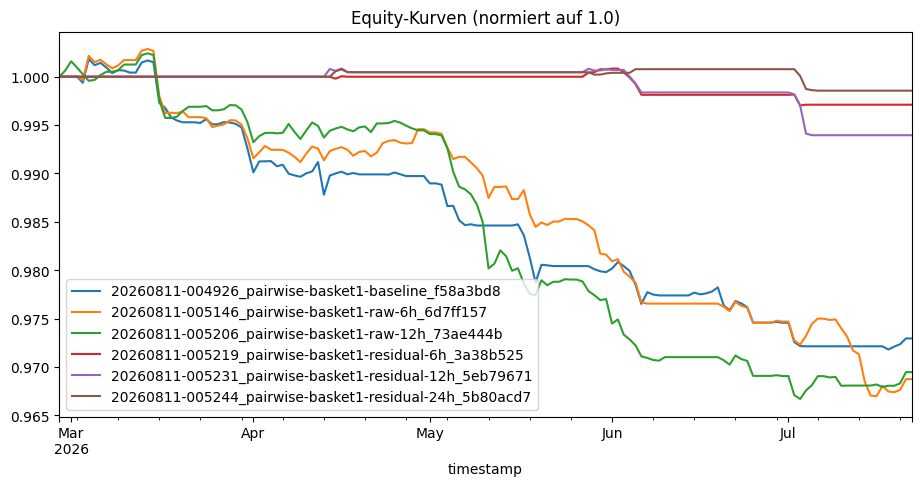

In [5]:
curves = bt_runs.compare_equity_curves(RUN_IDS)
curves.plot(figsize=(11, 5), title="Equity-Kurven (normiert auf 1.0)")

## Trade-Verteilung nach Exit-Grund

In [6]:
bt_runs.compare_trade_distributions(RUN_IDS)

,exit_reason,count,mean,sum,run_id
0,clique_break,15,-20.036969,-300.554535,20260811-004926_pairwise-basket1-baseline_f58a...
1,stop,35,-76.601483,-2681.051917,20260811-004926_pairwise-basket1-baseline_f58a...
2,target,17,56.634428,962.785279,20260811-004926_pairwise-basket1-baseline_f58a...
3,timeout,9,-76.229381,-686.064432,20260811-004926_pairwise-basket1-baseline_f58a...
4,clique_break,14,-21.071565,-295.001913,20260811-005146_pairwise-basket1-raw-6h_6d7ff157
5,stop,58,-58.044084,-3366.556879,20260811-005146_pairwise-basket1-raw-6h_6d7ff157
6,target,24,76.292408,1831.017797,20260811-005146_pairwise-basket1-raw-6h_6d7ff157
7,timeout,19,-68.176531,-1295.354096,20260811-005146_pairwise-basket1-raw-6h_6d7ff157
8,clique_break,16,1.797631,28.762099,20260811-005206_pairwise-basket1-raw-12h_73ae444b
9,stop,71,-51.621211,-3665.105988,20260811-005206_pairwise-basket1-raw-12h_73ae444b
